Import some libraries.

In [1]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from kneed import KneeLocator
from sklearn.cluster import AgglomerativeClustering

Load Dataset.

In [2]:
df=pd.read_csv("smart_cart.csv")
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,42,118,247,2,9,3,4,5,0,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,0,0,8,7,8,2,5,7,0,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,32,12,24,1,2,3,13,6,0,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,80,30,61,2,6,5,10,3,0,0


Checking some missing values.

In [3]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

Fill missing values with median.

In [4]:
df["Income"]=df["Income"].fillna(df["Income"].median())

Feature Engineering.

In [5]:
df["Age"]=2026-df["Year_Birth"]

In [6]:
df["Dt_Customer"]=pd.to_datetime(df["Dt_Customer"],dayfirst=True)
ref_date=df["Dt_Customer"].max()
df["Customer_Ternure_Days"]=(ref_date-df["Dt_Customer"]).dt.days

In [7]:
df["Total_Spending"]=df["MntWines"]+df["MntFruits"]+df["MntMeatProducts"]+df["MntFishProducts"]+df["MntSweetProducts"]+df["MntGoldProds"]


In [8]:
df["Total_Childrens"]=df["Kidhome"]+df["Teenhome"]

In [9]:
df["Education"].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

Categorical dara transformation.

In [10]:
df["Education"]=df["Education"].replace({
    "Graduation":"Graduate",
    "PhD":"Postgraduate",
    "Master":"Postgraduate",
    "2n Cycle":"Undergraduade",
    "Basic":"Undergraduade"
})

In [11]:
df["Education"].value_counts()

Education
Graduate         1127
Postgraduate      856
Undergraduade     257
Name: count, dtype: int64

In [12]:
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [13]:
df["Living_With"]=df["Marital_Status"].replace({
    "Married":"Partner",
    "Together":"Partner",
    "Single":"Alone",
    "Divorced":"Alone",
    "Widow":"Alone",
    "Absurd":"Alone",
    "YOLO":"Alone"
})
df["Living_With"].value_counts()

Living_With
Partner    1444
Alone       796
Name: count, dtype: int64

In [14]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Ternure_Days,Total_Spending,Total_Childrens,Living_With
0,5524,1957,Graduate,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1617,0,Alone
1,2174,1954,Graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,27,2,Alone
2,4141,1965,Graduate,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,776,0,Partner
3,6182,1984,Graduate,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,53,1,Partner
4,5324,1981,Postgraduate,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,422,1,Partner


In [15]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Ternure_Days',
       'Total_Spending', 'Total_Childrens', 'Living_With'],
      dtype='object')

Feature selection and column removal.

In [16]:
col=["ID"]+["Year_Birth"]+["Marital_Status"]+["Kidhome"]+["Teenhome"]+["Dt_Customer"]+["MntWines"]+["MntFruits"]+["MntMeatProducts"]+["MntFishProducts"]+["MntSweetProducts"]+["MntGoldProds"]

In [17]:
df_cleaned=df.drop(columns=col)

In [18]:
df_cleaned.columns

Index(['Education', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'Age',
       'Customer_Ternure_Days', 'Total_Spending', 'Total_Childrens',
       'Living_With'],
      dtype='object')

In [19]:
df_cleaned.shape

(2240, 15)

In [20]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Ternure_Days,Total_Spending,Total_Childrens,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


Exploratory data anaslysis.

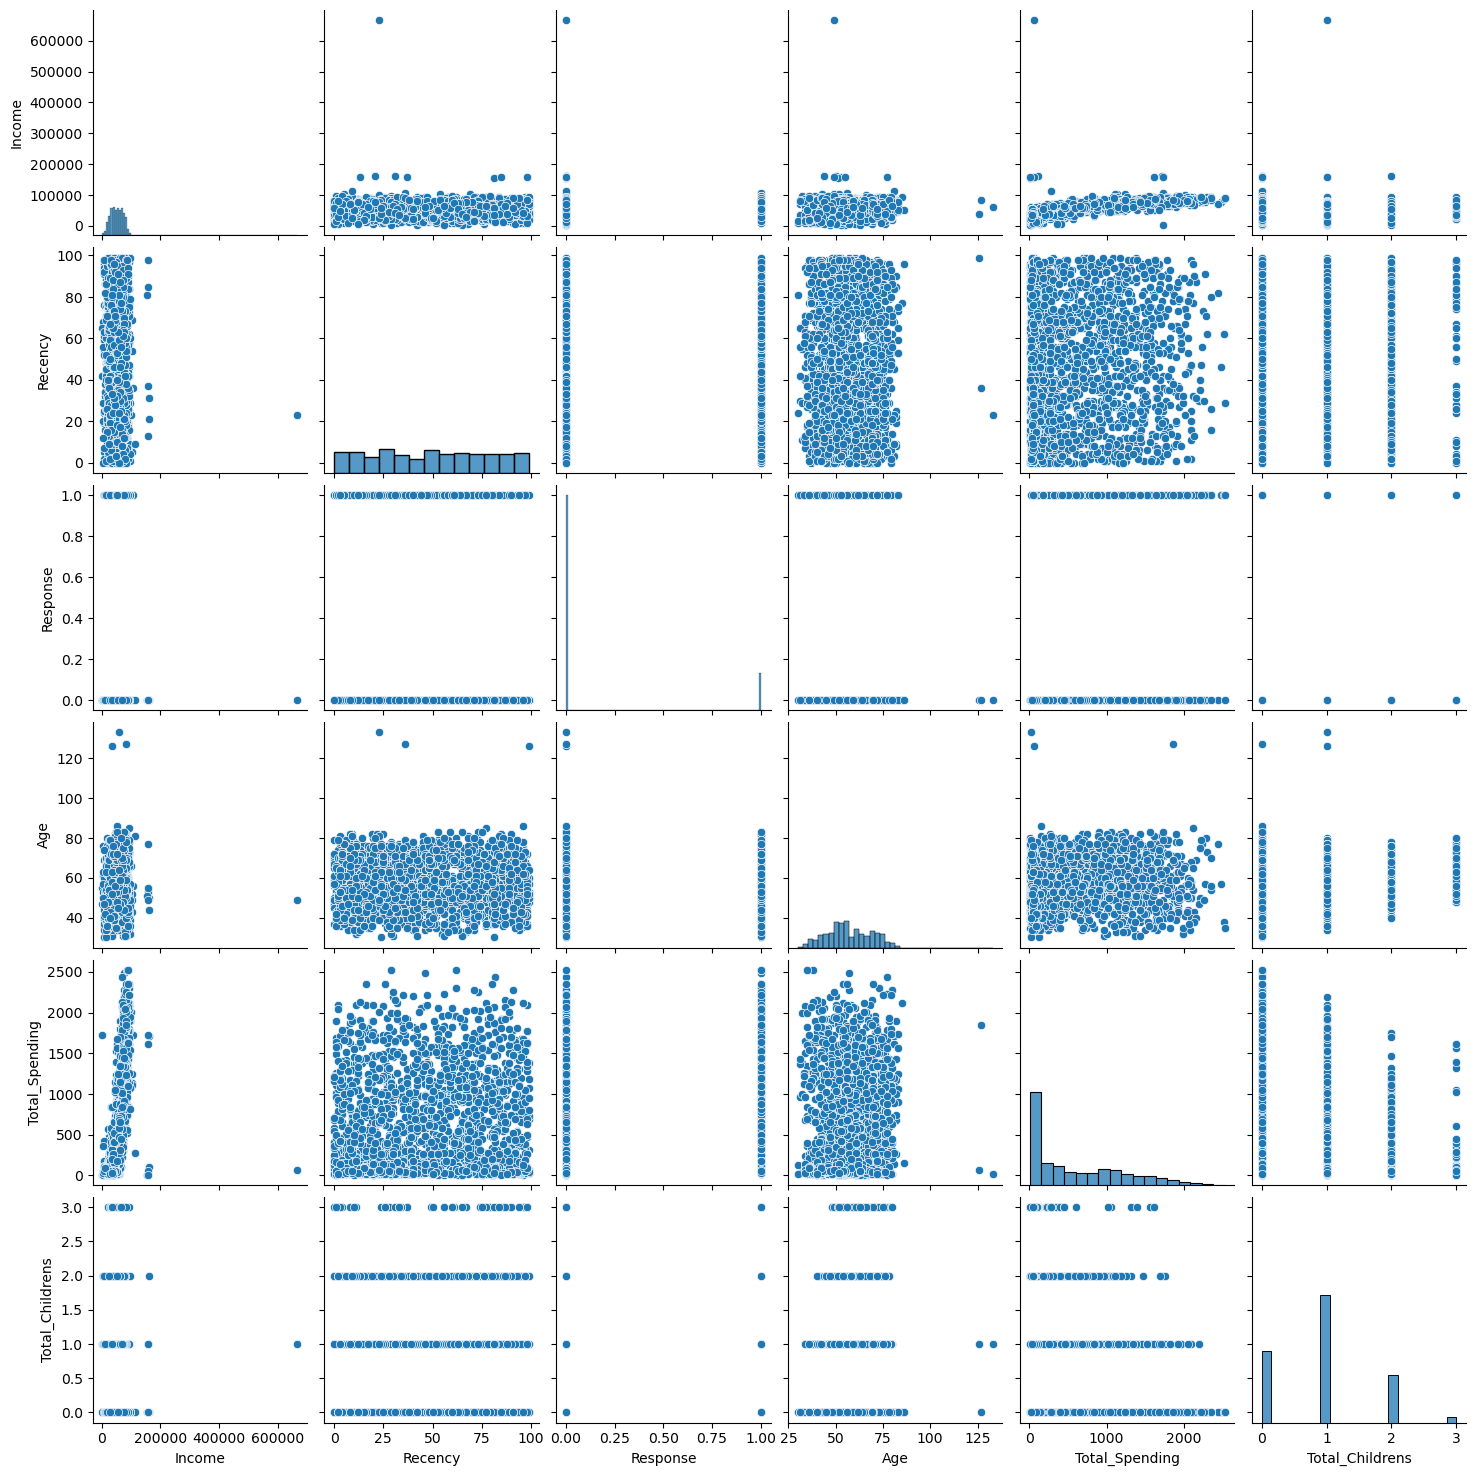

In [21]:
cols=["Income"]+["Recency"]+["Response"]+["Age"]+["Total_Spending"]+["Total_Childrens"]
sns.pairplot(df[cols])


Outlier treatment.

In [22]:
print("Data size with outliers",len(df_cleaned))
df_cleaned=df_cleaned[(df_cleaned["Age"]<90)]
df_cleaned=df_cleaned[(df_cleaned["Income"]<600000)]

print("Data size without outliers",len(df_cleaned))

Data size with outliers 2240
Data size without outliers 2236


Correlation analysis.

In [23]:
corr=df_cleaned.corr(numeric_only=True)

<Axes: >

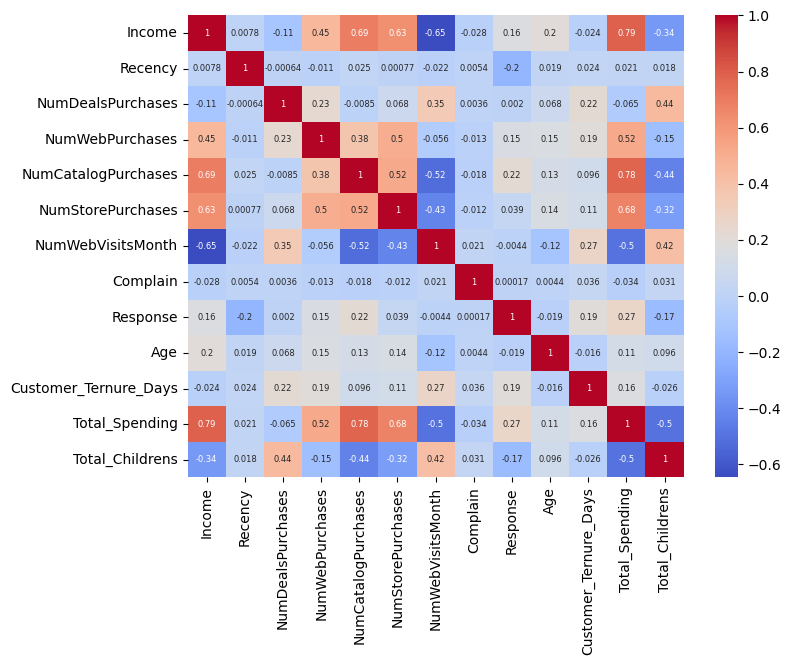

In [24]:
plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot_kws={"size":6},
    cmap="coolwarm",
    annot=True
)


One Hot Encoding.

In [25]:
ohe=OneHotEncoder()
cat_columns=["Education","Living_With"]
enc_columns=ohe.fit_transform(df_cleaned[cat_columns])
enc_df=pd.DataFrame(enc_columns.toarray(),columns=ohe.get_feature_names_out(cat_columns),index=df_cleaned.index)

In [26]:
enc_df.head()

,Education_Graduate,Education_Postgraduate,Education_Undergraduade,Living_With_Alone,Living_With_Partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


In [27]:
df_encoded=pd.concat([df_cleaned.drop(columns=cat_columns),enc_df],axis=1)

In [28]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Ternure_Days,Total_Spending,Total_Childrens,Education_Graduate,Education_Postgraduate,Education_Undergraduade,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


In [29]:
df_encoded.shape

(2236, 18)

Feature Scaling.

In [30]:
X=df_encoded

In [31]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

Principal component Analysis.

In [32]:
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)

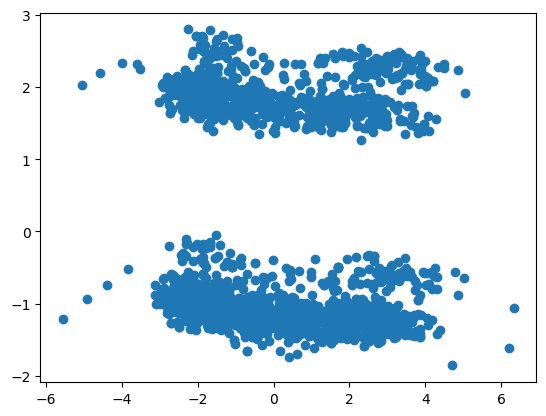

In [33]:
plt.scatter(X_pca[:,0],X_pca[:,1])

In [34]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454])

In [35]:
pca=PCA(n_components=3)
X_pca=pca.fit_transform(X_scaled)

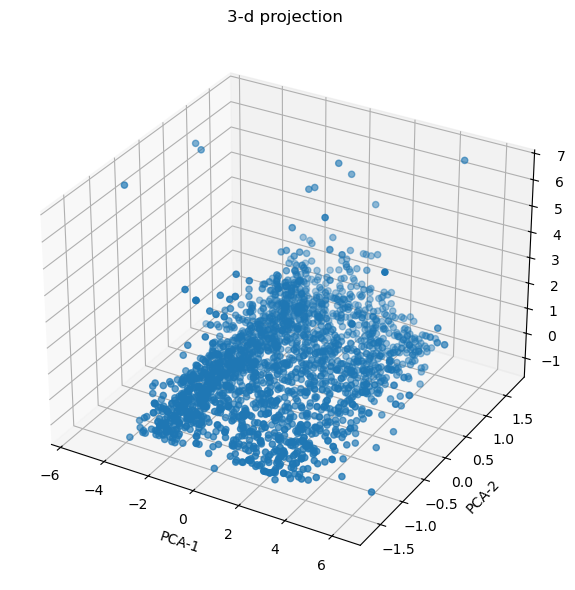

In [36]:
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(X_pca[:,0],X_scaled[:,1],X_scaled[:,2])
ax.set_xlabel("PCA-1")
ax.set_ylabel("PCA-2")
ax.set_zlabel("PCA-3")
ax.set_title("3-d projection")
plt.tight_layout()

Elbow method.

In [37]:
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=2):
    wcss=[]
    for k in range(1,11):
        kmeans=KMeans(n_clusters=k, random_state=42)
        kmeans.fit(X_pca)
        wcss.append(kmeans.inertia_)

In [38]:
knee=KneeLocator(range(1,11),wcss,curve="convex",direction="decreasing")
optimal_k=knee.elbow

Find best value of k.

In [39]:
print("Best k value",optimal_k)

Best k value 4


Graph to find best value of k.

Text(0, 0.5, 'wcss value')

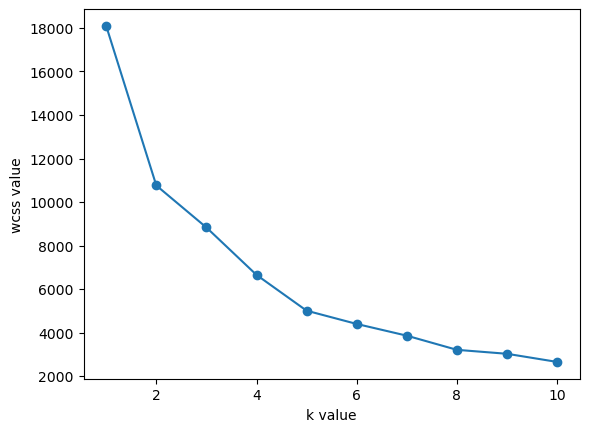

In [40]:
plt.plot(range(1,11),wcss,marker="o")
plt.xlabel("k value")
plt.ylabel("wcss value")

Silhouette Score method.

In [41]:
from threadpoolctl import threadpool_limits
scores=[]
with threadpool_limits(limits=2):
    for k in range(2,11):
        kmeans=KMeans(n_clusters=k,random_state=42)
        labels=kmeans.fit_predict(X_pca)
        score=silhouette_score(X_pca,labels)
        scores.append(score)

Graph of Silhouette Score.

Text(0, 0.5, 'Silhouette Score')

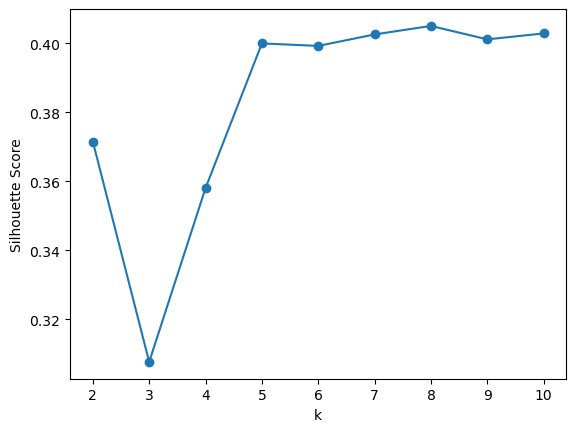

In [42]:
plt.plot(range(2,11),scores,marker="o")
plt.xlabel("k")
plt.ylabel("Silhouette Score")

Comparision of both the graphs.

Text(0, 0.5, 'SS')

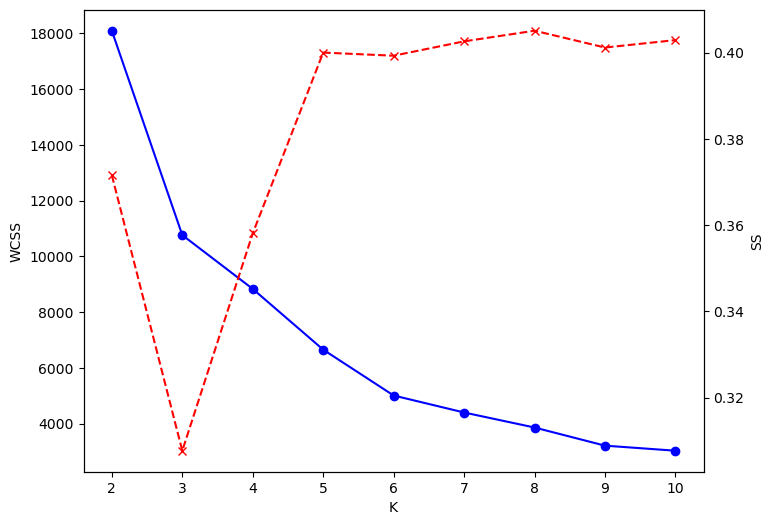

In [43]:
k_range=range(2,11)
fig,ax1=plt.subplots(figsize=(8,6))
ax1.plot(k_range,wcss[:len(k_range)],marker="o",color="blue")
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2=ax1.twinx()
ax2.plot(k_range,scores[:len(k_range)],marker="x",color="red",linestyle="--")
ax2.set_ylabel("SS")

K-Means Clustring.

In [44]:
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=2):
    k_means=KMeans(n_clusters=4,random_state=42)
    labels_kmeans=k_means.fit_predict(X_pca)

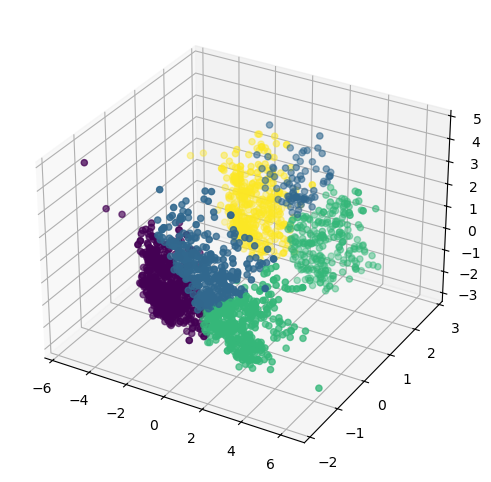

In [45]:
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c=labels_kmeans)

Agglomerative clustring.

In [46]:
agg_clu=AgglomerativeClustering(n_clusters=4,linkage="ward")
labels_agg=agg_clu.fit_predict(X_pca)

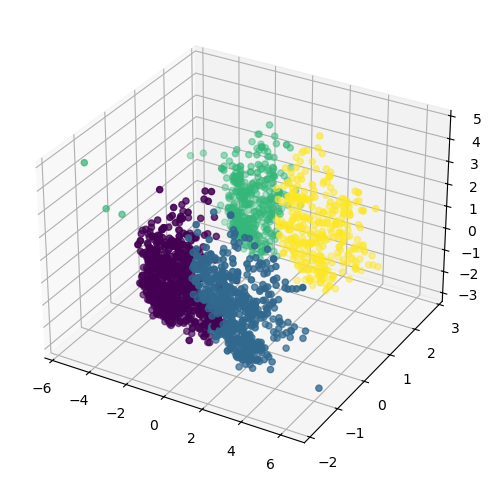

In [47]:
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c=labels_agg)

Customer Segmentation Analysis.

In [48]:
X["clusters"]=labels_agg
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Ternure_Days,Total_Spending,Total_Childrens,Education_Graduate,Education_Postgraduate,Education_Undergraduade,Living_With_Alone,Living_With_Partner,clusters
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='clusters', ylabel='count'>

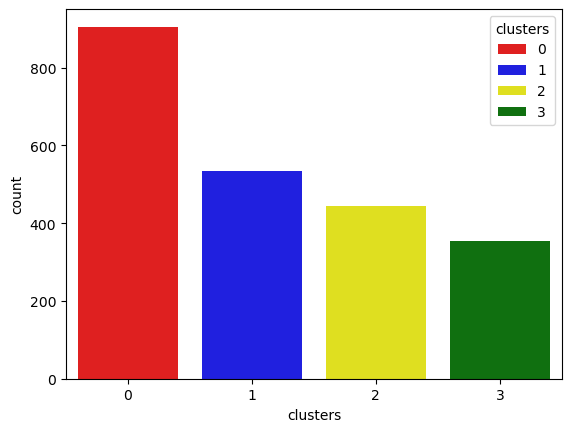

In [49]:
pal=["red","blue","yellow","green"]
sns.countplot(x=X["clusters"],palette=pal,hue=X["clusters"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

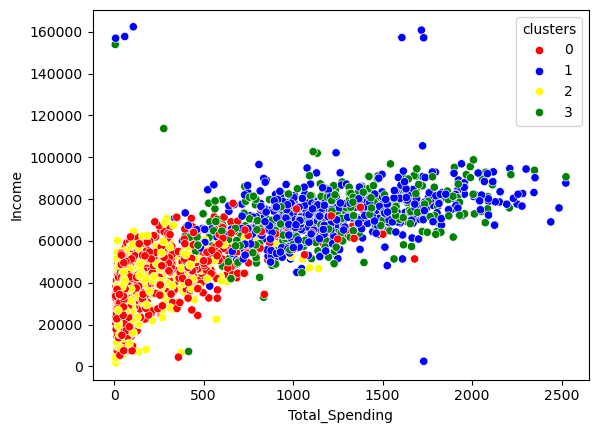

In [50]:
sns.scatterplot(x=X["Total_Spending"],y=X["Income"],hue=X["clusters"],palette=pal)

Cluster Summary.

In [51]:
clu_summary=X.groupby("clusters").mean()
print(clu_summary)

                Income    Recency  NumDealsPurchases  NumWebPurchases  \
clusters                                                                
0         39680.580110  48.914917           2.594475         3.153591   
1         72808.445693  49.202247           1.958801         5.687266   
2         36960.143018  48.319820           2.594595         2.713964   
3         70722.681303  50.504249           1.855524         5.790368   

          NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
clusters                                                                        
0                    0.969061           4.143646           6.307182  0.011050   
1                    5.498127           8.659176           3.580524  0.005618   
2                    0.837838           3.623874           6.659910  0.011261   
3                    5.014164           8.430595           3.728045  0.005666   

          Response        Age  Customer_Ternure_Days  Total_Spending  \
cl